# RV of a spot and a facula transit: gaussian fit vs template matching (Bouchy et al. 2001)

The CCFs of a spot transit and of a facula transit (MURaM spectra, same setup as the tutorial) are measured in two ways:

1. **gaussian fit**: SunSim now (`compute_ccf_params`), the mean of a gaussian + offset fitted to the CCF.
2. **template matching** (Bouchy, Pepe & Queloz 2001): the CCF C is compared pixel by pixel with a template T, the disc-integrated CCF of the quiet star. For a small shift, C(v) = T(v − RV) ≈ T(v) − RV T′(v), so
   1. the derivative of the template, T′ = dT/dv;
   2. every pixel i of the window gives a shift $v_i = -(C_i - T_i)\,/\,T'_i$;
   3. the RV is the mean of the $v_i$ weighted by $W_i = T_i'^2$:
   $$\mathrm{RV} = \frac{\sum_i W_i\, v_i}{\sum_i W_i} = -\frac{\sum_i (C_i - T_i)\, T'_i}{\sum_i T_i'^2}.$$

Both RVs are relative to the quiet star (0 for the quiet star).

Notes on the template method:
- **Weights.** The sum is divided by Σ W_i, not by the number of pixels N. Σ W_i v_i / N is RV × mean(W): it is in m/s × (dC/dv)², not m/s. With photon noise, W_i = T′_i² / σ_i² (Bouchy eq. 8). The CCFs here are noise-free, so σ_i is constant.
- **No division by T′.** At the peak and in the continuum T′ ≈ 0: v_i diverges but its weight is 0. The second form of the formula has no division by T′, so it is used.
- **Normalisation.** A dark spot lowers the flux of the star and so the amplitude of the CCF, and a factor a on C would change the RV into a × RV. Before the comparison, every CCF is scaled to the area of the template (C → C ΣT / ΣC), which a pure shift does not change.
- **Window.** The same as the gaussian fit: the points between the wings of the first CCF (`speed_bisector_nb`, as in `compute_ccf_params`).

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import time as timer
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

from sunsim import *
from sunsim import local_path, nbspectra

## 1. Star, spectra and CCF grids

As in sections 2.4 and 7 of the tutorial:
- **Spectra**: MURaM high resolution spectra of the quiet photosphere and of the faculae (200 G). The spot spectrum is the quiet one (vx-drift corrected SSD) times the black-body ratio for ΔT = 500 K.
- **CCF setup**: HARPS G2 mask, 30 rings. The Dumusque bisector is added to the spot only.
- **Time series**: one rotation with 121 epochs. The regions are on the equator at longitude 180°: they cross the centre of the disc at t = P/2, and none is visible at t = 0.

In [2]:
rotation_period = 24.47            # [days]
inclination = 0                    # [rad] equator-on
T_quiet = 5770                     # [K]
spot_dT = 700                      # [K]
N_rings = 100
time = np.linspace(0, rotation_period, 121)

flux_quiet = np.load(str(local_path('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_fc = np.load(str(local_path('muram_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_sp = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
for mu in flux_sp:
    flux_sp[mu]['intensity'] *= black_body(flux_sp[mu]['wav'], T_quiet - spot_dT) / black_body(flux_sp[mu]['wav'], T_quiet)

wvm, fm = mask_weights(str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'))
rv_grid = np.arange(-18000, 18025, 25)             # [m/s]

def make_ccf_grid(flux, cb, bisector):
    g = CCF_grid(N_rings, flux, rv_grid, wvm, fm, convective_blueshift=cb, phoenix_resolution=True, normalization=False)
    g.built_grid(bisector=bisector)
    return g

ccf_quiet = make_ccf_grid(flux_quiet, 0, None)
ccf_fac = make_ccf_grid(flux_fc, 0, None)
ccf_spot = make_ccf_grid(flux_sp, 1, dumusque_bisector(normalization=False))

## 2. Simulations, template and window

`quiet` has no region: its CCF is the template (the same at every epoch). The first epoch of `spot` and `facula` is also the quiet star (checked).

In [3]:
scenarios = {
    'quiet':  [],
    'spot':   [active_region('sp', 10, 90, 180)],
    'facula': [active_region('fc', 10, 90, 180)],
}
sims = {}
for name, regions in scenarios.items():
    ss = StarSim(time, N_rings, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=SOLAR_DIFFERENTIAL_ROTATION, active_regions_map=regions, mode=['ccf'],
                 stellar_radius=1, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
    ss.generate_timeseries(verbose=False)
    sims[name] = ss

rv = sims['quiet'].ccf_rv
template = sims['quiet'].ccf_var[0]
for name in ('spot', 'facula'):
    assert np.allclose(sims[name].ccf_var[0], template, rtol=1e-12, atol=0), name

# window of the gaussian fit (compute_ccf_params): between the wings of the first CCF
c0 = template - template.min() + 0.000001
cutleft, cutright, _, _ = nbspectra.speed_bisector_nb(np.ascontiguousarray(rv, dtype=np.float64), c0 / c0.max(), True)
window = np.zeros(len(rv), dtype=bool)
window[int(cutleft):int(cutright)] = True
print('template: RV = %.1f m/s, FWHM = %.1f m/s (gaussian fit), vsini = %.0f m/s'
      % (sims['quiet'].rv_var[0], sims['quiet'].fwhm_var[0], sims['quiet'].vsini))
print('window: %.2f to %.2f km/s (%d points)' % (rv[window][0] / 1e3, rv[window][-1] / 1e3, window.sum()))

template: RV = -968.2 m/s, FWHM = 6989.8 m/s (gaussian fit), vsini = 2069 m/s
window: -10.50 to 8.95 km/s (779 points)


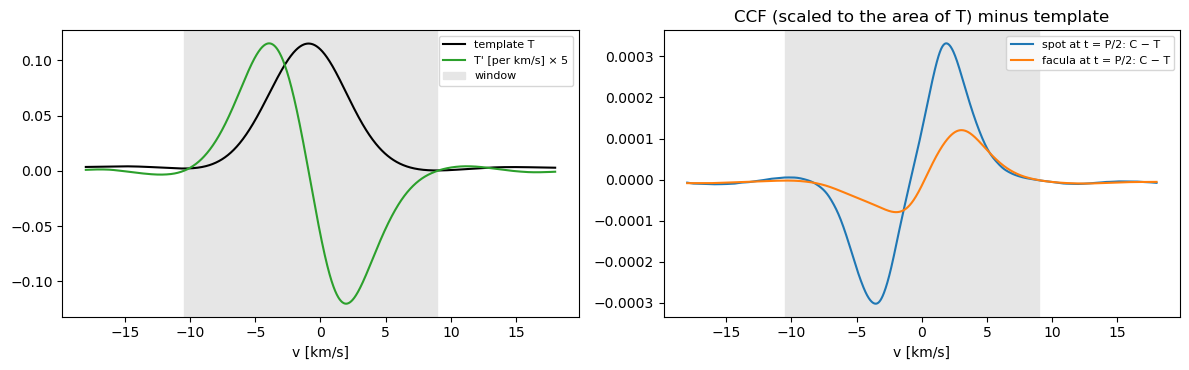

In [4]:
# SunSim CCFs are peaks (the inverted line). Left: template, its derivative and the window. Right: CCF minus template
# at the centre of the transit, and the shift alone (-RV T') that template matching fits to it.
dT = CubicSpline(rv, template)(rv, 1)
k_c = np.argmin(np.abs(time - rotation_period / 2))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(rv / 1e3, template, 'k', label='template T')
ax[0].plot(rv / 1e3, dT * 1e3 * 5, 'C2', label="T' [per km/s] × 5")
ax[0].axvspan(rv[window][0] / 1e3, rv[window][-1] / 1e3, color='0.9', zorder=0, label='window')
ax[0].set_xlabel('v [km/s]'); ax[0].legend(fontsize=8)
for j, name in enumerate(('spot', 'facula')):
    c = sims[name].ccf_var[k_c]
    c = c * template.sum() / c.sum()
    ax[1].plot(rv / 1e3, c - template, 'C%d' % j, label='%s at t = P/2: C − T' % name)
ax[1].axvspan(rv[window][0] / 1e3, rv[window][-1] / 1e3, color='0.9', zorder=0)
ax[1].set_xlabel('v [km/s]'); ax[1].set_title('CCF (scaled to the area of T) minus template'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Template matching

In [5]:
def template_rv(rv, ccfs, template, window):
    """RV of every CCF (rows of ccfs) relative to the template (Bouchy et al. 2001), on the points of window:
    every CCF is scaled to the area of the template, then v_i = -(C_i - T_i) / T'_i for every point i and
    RV = sum(W_i v_i) / sum(W_i) with W_i = T'_i^2, computed as -sum((C_i - T_i) T'_i) / sum(T'_i^2)."""
    ccfs = np.atleast_2d(ccfs)
    ccfs = ccfs * (template.sum() / ccfs.sum(axis=1))[:, None]
    dT = CubicSpline(rv, template)(rv, 1)[window]       # 1. dT/dv
    diff = ccfs[:, window] - template[window]            # 2. C_i - T_i (v_i = -diff / dT)
    W = dT**2                                            # 3. weights
    return -np.sum(diff * dT, axis=1) / np.sum(W)

### Check: the template shifted by known RVs

The template is shifted by RV and its amplitude multiplied by 0.98, which the area normalisation must remove. The method is linear in the shift (first order Taylor expansion), so it loses accuracy when the shift is no longer small compared with the width of the CCF (≈ 7 km/s).

In [6]:
spl = CubicSpline(rv, template)
shifts = np.array([1, 5, 20, -50, 100, 300])                    # [m/s]
fake = np.array([0.98 * spl(rv - s) for s in shifts])
rv_t = template_rv(rv, fake, template, window)
for s, r in zip(shifts, rv_t):
    print('injected %5.0f m/s -> template matching %9.4f m/s (error %+.4f m/s)' % (s, r, r - s))

injected     1 m/s -> template matching    1.0000 m/s (error -0.0000 m/s)
injected     5 m/s -> template matching    5.0000 m/s (error -0.0000 m/s)
injected    20 m/s -> template matching   19.9995 m/s (error -0.0005 m/s)
injected   -50 m/s -> template matching  -49.9983 m/s (error +0.0017 m/s)
injected   100 m/s -> template matching   99.9640 m/s (error -0.0360 m/s)
injected   300 m/s -> template matching  299.1672 m/s (error -0.8328 m/s)


## 4. Spot and facula transits

The gaussian RV is relative to the first epoch (the quiet star), the template RV is relative to the template (also the quiet star). Time from the crossing of the disc centre.

In [7]:
res = {}
for name in ('spot', 'facula'):
    ss = sims[name]
    t0 = timer.perf_counter(); rv_g, *_ = ss.compute_ccf_params(); tG = timer.perf_counter() - t0
    t0 = timer.perf_counter(); rv_t = template_rv(rv, ss.ccf_var, template, window); tT = timer.perf_counter() - t0
    res[name] = dict(gauss=rv_g - rv_g[0], template=rv_t)
    print('%-7s %d CCFs: gaussian fit + bisector %.4f s, template matching %.4f s' % (name, len(ss.ccf_var), tG, tT))

spot    121 CCFs: gaussian fit + bisector 0.0062 s, template matching 0.0028 s
facula  121 CCFs: gaussian fit + bisector 0.0043 s, template matching 0.0008 s


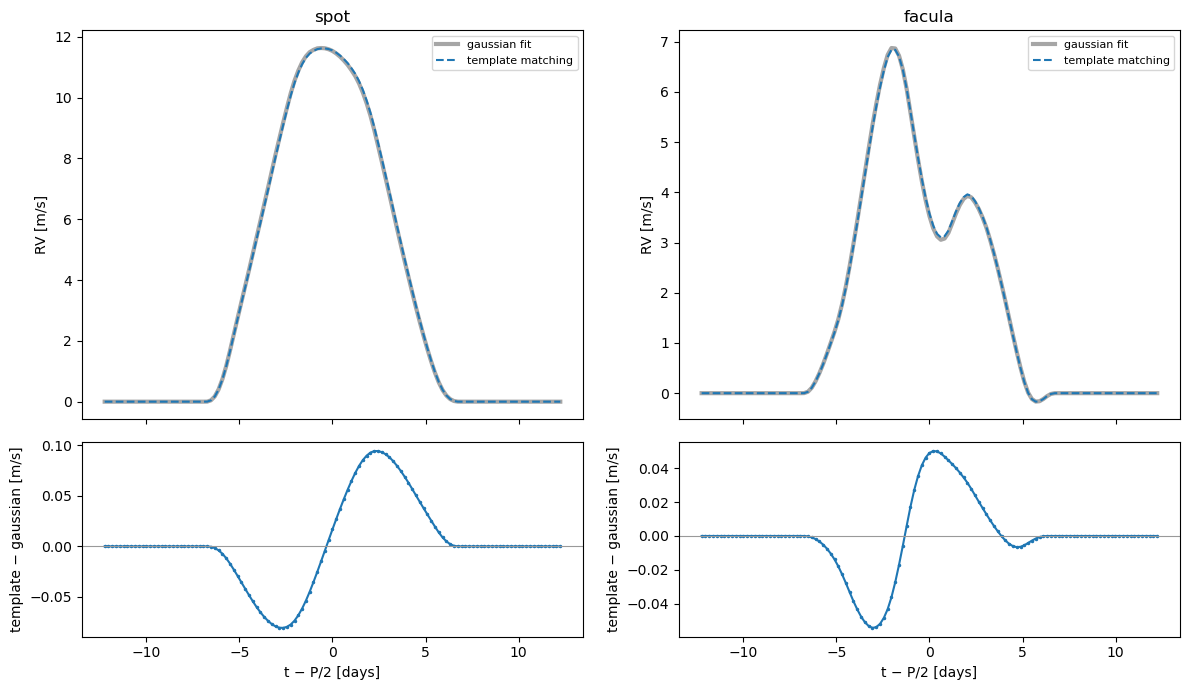

In [8]:
th = time - rotation_period / 2
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j, name in enumerate(('spot', 'facula')):
    r = res[name]
    ax = axes[0, j]
    ax.plot(th, r['gauss'], 'k-', lw=3, alpha=0.35, label='gaussian fit')
    ax.plot(th, r['template'], 'C0--', label='template matching')
    ax.set_ylabel('RV [m/s]'); ax.set_title(name); ax.legend(fontsize=8)
    ax = axes[1, j]
    ax.plot(th, r['template'] - r['gauss'], 'C0.-', ms=3)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set_ylabel('template − gaussian [m/s]'); ax.set_xlabel('t − P/2 [days]')
plt.tight_layout(); plt.show()

In [9]:
for name in ('spot', 'facula'):
    g, t = res[name]['gauss'], res[name]['template']
    d = t - g
    print('%-7s peak to peak: gaussian %.3f m/s, template %.3f m/s | template - gaussian: rms %.3f m/s, max |diff| %.3f m/s'
          % (name, np.ptp(g), np.ptp(t), np.std(d), np.max(np.abs(d))))

spot    peak to peak: gaussian 11.631 m/s, template 11.619 m/s | template - gaussian: rms 0.042 m/s, max |diff| 0.094 m/s
facula  peak to peak: gaussian 7.041 m/s, template 7.006 m/s | template - gaussian: rms 0.022 m/s, max |diff| 0.054 m/s


## 5. Summary

Noise-free simulations; the template comes from the same grids as the CCFs. Numbers from the outputs above.

**Check.** Shifts up to 50 m/s are recovered to better than 0.002 m/s. The amplitude factor of 0.98 is removed by the area normalisation (without it the RVs would be 2 % too small). The method is first order in the shift: the error is 0.04 m/s at 100 m/s and 0.8 m/s at 300 m/s. For large shifts the template would have to be shifted by the RV found and the comparison redone.

**Transits.** Template matching gives the same RV as the gaussian fit:

| region | peak to peak | rms difference | maximum difference |
|---|---|---|---|
| spot | 11.7 m/s | 0.042 m/s | 0.09 m/s (< 1 %) |
| facula | 7.0 m/s | 0.022 m/s | 0.05 m/s (< 1 %) |

The difference is antisymmetric around the crossing of the disc centre: negative at ingress, positive at egress. The two methods weight the asymmetric part of the change of the CCF differently. The gaussian fit weights it by the derivative of a gaussian, template matching by the derivative of the real CCF. For these nearly gaussian solar CCFs, the template brings no significant change in RV.

**Cost.** 0.5 ms for 121 CCFs, against 2.5 ms for the gaussian fit + bisector.

**Not tested here:** photon noise (weights T′²/σ², for which Bouchy et al. give the RV uncertainty), and CCFs far from a gaussian (M dwarfs, fast rotators), where the two RVs could differ more.

## 6. Contrast, FWHM and BIS with the template

The same idea as section 3: every indicator is a linear function of C − T, computed once from the template and applied to all the epochs with one matrix product. First order in the change of the CCF.

**Contrast, RV and FWHM: joint least squares** on the window (the generalisation of Bouchy, whose only basis function is T′):
$$C - T \approx b + a\,T - \mathrm{RV}\,T' - s\,(v - v_0)\,T'$$
- $b + a\,T$: offset and scale. `compute_ccf_params` fits the amplitude of C − min(C), so the offset cancels and the amplitude is multiplied by 1 + a: **Δcontrast = a × contrast(T)**. This term replaces the area normalisation of section 3 (the area normalisation would remove the contrast change).
- $-s\,(v - v_0)\,T'$: a stretch of the profile around its centre $v_0$, $T(v_0 + (v - v_0)/(1 + s)) \approx T - s\,(v - v_0)\,T'$: **ΔFWHM = s × FWHM(T)**, what a gaussian fit sees for a stretch. T and $(v - v_0)T'$ are both even, so a and s must be fitted together; T′ is odd and nearly orthogonal to them. $v_0$ = centre of the gaussian fit of T, so that RV is a shift of the centre.
- **Scale.** For C = (1 + a) T(v − RV) + b the coefficient of −T′ is (1 + a) RV, not RV: RV, s and the flank shifts below are divided by 1 + a (the derivative of the scaled template). Without it, a contrast change of −10 % gives a RV 10 % too small.

**BIS: Bouchy's $v_i$ averaged over the bisector bands.** $v_i = -(C_i - T_i)/T'_i$ is how far the flank moves at the height of pixel i. `compute_ccf_params` takes the heights relative to the minimum and the maximum of the CCF, $y = (C - C_\min)/(C_\max - C_\min)$, so at a fixed y the change of the CCF is corrected for the change of its minimum and maximum:
$$D_i = \Delta C_i - \Delta C_{\min} - y_i\,(\Delta C_{\max} - \Delta C_{\min}), \qquad \delta v_i = -D_i / T'_i$$
($D = 0$ for a pure scale and offset, as the BIS). The bisector gives the same weight to every height, and $dy \propto |T'|\,dv$, so the mean shift of a flank over a band of heights is the mean of $\delta v_i$ weighted by $|T'_i|$, without any division by T′:
$$\langle \delta v \rangle_\mathrm{band} = -\frac{\sum_\mathrm{band} \mathrm{sgn}(T'_i)\, D_i}{\sum_\mathrm{band} |T'_i|}$$
The bisector at a height is the mean of the two flanks, so **ΔBIS = ½(⟨δv⟩_L + ⟨δv⟩_R)_bottom − ½(⟨δv⟩_L + ⟨δv⟩_R)_top**, with the bands of `compute_ccf_params` (heights 10–40 % and 60–90 %). A pure shift moves both bands by RV and cancels.

**Width at half height** (another FWHM, in the same way as the BIS): ⟨δv⟩_R − ⟨δv⟩_L on the heights 45–55 %. It measures the flanks directly, not the gaussian fit.

In [10]:
def template_indicators(rv, ccfs, template, window, v0):
    """Changes of contrast, RV, FWHM and BIS of every CCF (rows of ccfs) relative to the template, first order in C - T.
    Joint least squares on window: C - T = b + a T - RV T' - s (v - v0) T' (a: relative change of the contrast, s:
    relative change of the FWHM); RV and s are divided by 1 + a (the derivative of the scaled template). BIS: mean flank shifts dv_i = -D_i / T'_i over the heights 10-40 % and 60-90 % (as compute_ccf_params), weight
    |T'_i|, with D = C - T corrected for the change of the minimum and the maximum of the CCF (the heights of the
    bisector are relative to them). fwhm_half: change of the width at half height (flanks between 45 and 55 %).
    Returns a dict of arrays: a, b, rv, s, bis, fwhm_half."""
    ccfs = np.atleast_2d(ccfs)
    dC = ccfs - template
    dT = CubicSpline(rv, template)(rv, 1)
    # 1. joint least squares
    X = np.column_stack([np.ones(window.sum()), template[window], -dT[window], -(rv[window] - v0) * dT[window]])
    (b, a, rv_fit, s), *_ = np.linalg.lstsq(X, dC[:, window].T, rcond=None)
    rv_fit, s = rv_fit / (1 + a), s / (1 + a)              # C = (1 + a) T(v - RV) + b: the shift terms scale with 1 + a
    # 2. flank shifts at a fixed relative height
    i_min, i_max = np.argmin(template), np.argmax(template)
    y = (template - template[i_min]) / (template[i_max] - template[i_min])
    D = (dC - dC[:, [i_min]] - y * (dC[:, [i_max]] - dC[:, [i_min]])) / (1 + a)[:, None]
    c = template - template.min() + 0.000001
    _, _, _, ybis = nbspectra.speed_bisector_nb(np.ascontiguousarray(rv, dtype=np.float64), c / c.max(), True)
    left, right = window & (rv < rv[i_max]), window & (rv > rv[i_max])
    def shift(flank, lo, hi):                              # mean shift of a flank between the heights lo and hi
        sel = flank & (y >= lo) & (y <= hi)
        return -np.sum(np.sign(dT[sel]) * D[:, sel], axis=1) / np.sum(np.abs(dT[sel]))
    def bisector(lo, hi):                                  # mean bisector shift between the heights lo and hi
        return 0.5 * (shift(left, lo, hi) + shift(right, lo, hi))
    minccf = (ybis[0] - 0.1) / 0.9                         # higher wing minimum: bands of nbspectra.bisector_span_nb
    bis = bisector(max(0.1, minccf + 0.05 * (1 - minccf)), 0.4) - bisector(0.6, 0.9)
    fwhm_half = shift(right, 0.45, 0.55) - shift(left, 0.45, 0.55)
    return dict(a=a, b=b, rv=rv_fit, s=s, bis=bis, fwhm_half=fwhm_half)


rv_T, con_T, fwhm_T, bis_T, *_ = sims['quiet'].compute_ccf_params(ccf=template[None, :])
rv_T, con_T, fwhm_T, bis_T = rv_T[0], con_T[0], fwhm_T[0], bis_T[0]
print('template: RV %.1f m/s, contrast %.4g, FWHM %.1f m/s, BIS %.2f m/s' % (rv_T, con_T, fwhm_T, bis_T))


def compare(ccfs):
    """Changes relative to the template: compute_ccf_params (gaussian fit + bisector) and template_indicators."""
    rv_g, con_g, fwhm_g, bis_g, *_ = sims['quiet'].compute_ccf_params(ccf=np.vstack([template, ccfs]))  # window of T
    t = template_indicators(rv, ccfs, template, window, rv_T)
    return dict(contrast_gauss=con_g[1:] / con_T - 1, contrast_template=t['a'],
                rv_gauss=rv_g[1:] - rv_T, rv_template=t['rv'], rv_bouchy=template_rv(rv, ccfs, template, window),
                fwhm_gauss=fwhm_g[1:] - fwhm_T, fwhm_template=t['s'] * fwhm_T, fwhm_half=t['fwhm_half'],
                bis_gauss=bis_g[1:] - bis_T, bis_template=t['bis'])

template: RV -968.2 m/s, contrast 0.1149, FWHM 6989.8 m/s, BIS -44.34 m/s


### Check: known deformations of the template

$C(v) = (1 + a)\,T\big(v_0 + (v - v_0)/(1 + s) - \mathrm{RV} - \varepsilon\,y_T(v)\big) + b$: scale a, offset b (as a fraction of the maximum of T), shift RV, stretch s and a shift that grows with the height ($\varepsilon\,y_T$, 0 at the bottom and ε at the top: a tilted bisector, ΔBIS ≈ −ε/2). Every deformed CCF is measured with `compute_ccf_params` (the reference) and with the template. Contrast: relative change [%]; RV, FWHM, BIS: changes [m/s].

In [11]:
import pandas as pd
spl = CubicSpline(rv, template)
yT = (template - template.min()) / (template.max() - template.min())
cases = {                     # a, b / max(T), RV [m/s], s, eps [m/s]
    'shift 10 m/s':          (0, 0, 10, 0, 0),
    'scale -2 %, offset +1 %': (-0.02, 0.01, 0, 0, 0),
    'stretch 1e-3':          (0, 0, 0, 1e-3, 0),
    'bisector eps 10 m/s':   (0, 0, 0, 0, 10),
    'all together':          (-0.02, 0.01, 10, 1e-3, 10),
    'all x 5':               (-0.1, 0.05, 50, 5e-3, 50),
}
fake = np.array([(1 + a) * spl(rv_T + (rv - rv_T) / (1 + s) - r - e * yT) + b * template.max()
                 for a, b, r, s, e in cases.values()])
chk = pd.DataFrame(compare(fake), index=list(cases))
chk[['contrast_gauss', 'contrast_template']] *= 100
pd.options.display.float_format = '{:.4f}'.format
chk

,contrast_gauss,contrast_template,rv_gauss,rv_template,rv_bouchy,fwhm_gauss,fwhm_template,fwhm_half,bis_gauss,bis_template
shift 10 m/s,-0.0024,-0.0006,9.9994,9.9996,9.9999,-0.2835,0.0378,0.0907,0.0041,0.0013
"scale -2 %, offset +1 %",-2.0000,-2.0000,-0.0000,0.0000,0.4798,-0.0000,0.0000,0.0000,-0.0000,-0.0000
stretch 1e-3,0.0013,-0.0001,0.0019,-0.0000,0.0731,7.1425,6.9835,6.9644,-0.0435,-0.0470
bisector eps 10 m/s,-0.0009,0.0009,5.4406,5.4429,5.4432,-0.0694,0.0816,0.0918,-4.9980,-4.9960
all together,-2.0022,-2.0006,15.4517,15.4466,15.2977,6.7555,7.1604,7.2127,-5.0477,-5.0100
all x 5,-10.0191,-10.0366,77.4557,77.3121,63.9371,32.7790,38.0633,38.6126,-25.3828,-24.3785


### Spot and facula transits

`compute_ccf_params` relative to the first epoch (the quiet star), the template indicators relative to the template (also the quiet star).

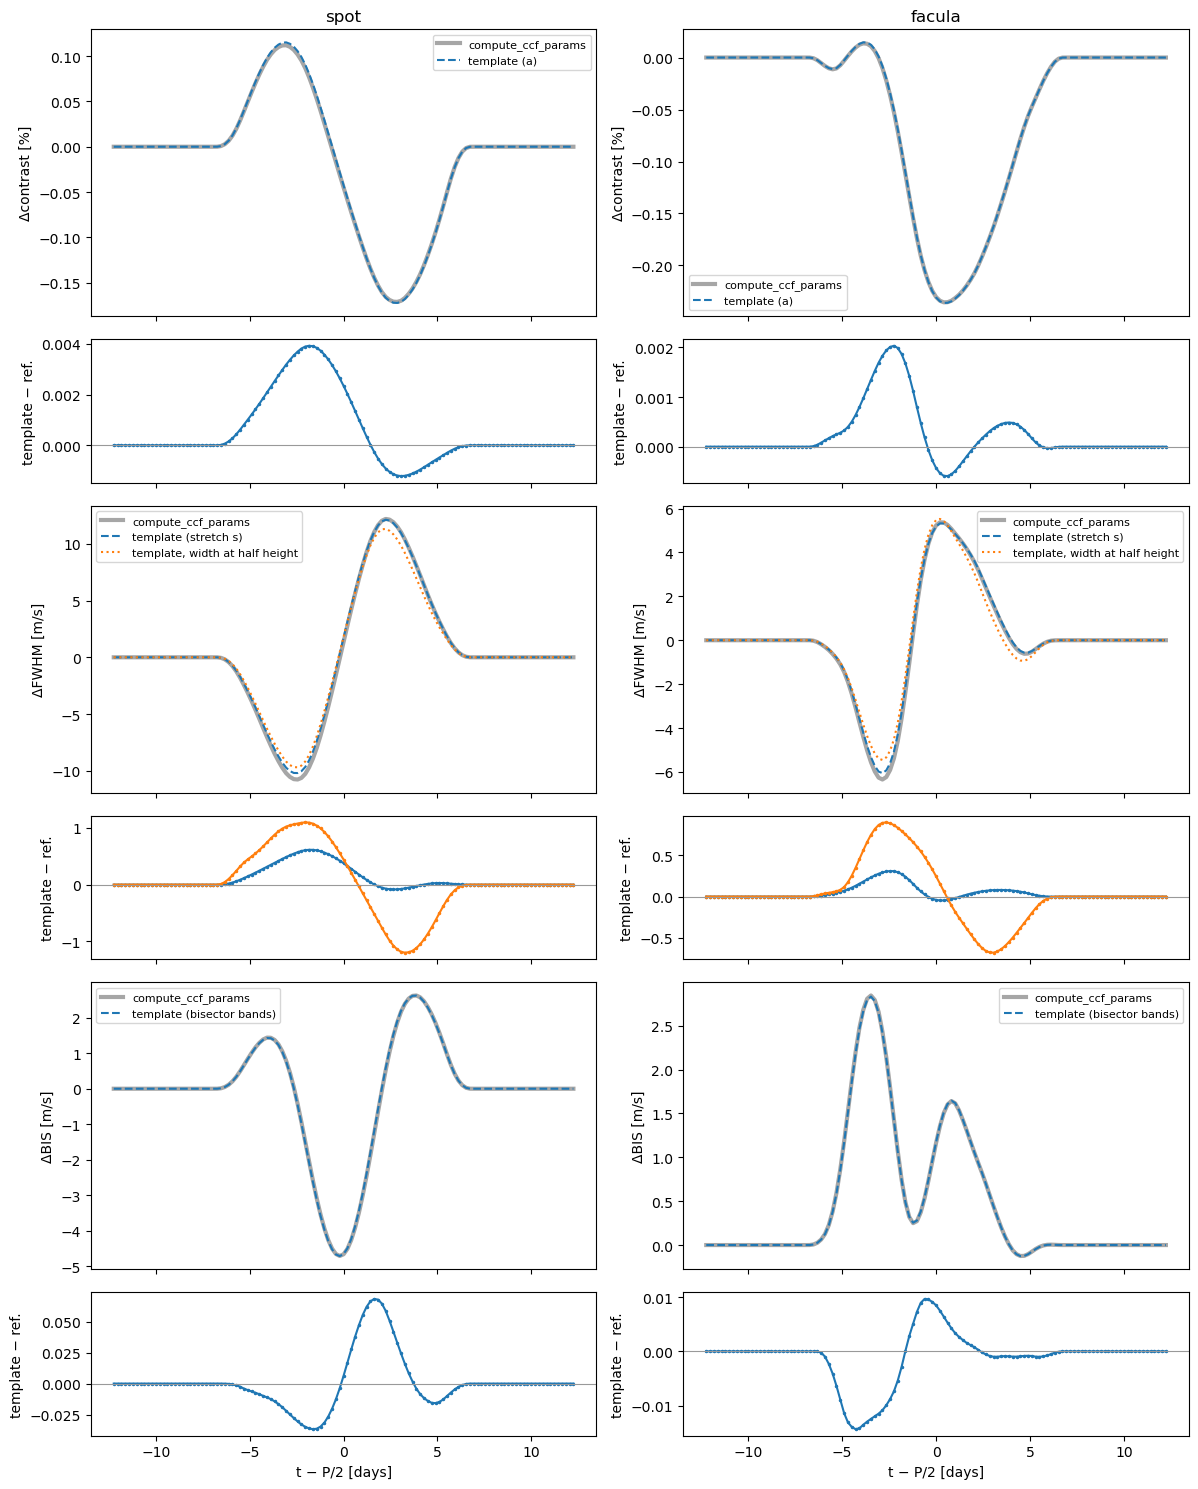

spot    contrast peak to peak 0.2830 % | contrast_template - ref: rms 0.0014, max 0.0039
spot    rv       peak to peak 11.6313 m/s | rv_template - ref: rms 0.0069, max 0.0174 | rv_bouchy - ref: rms 0.0421, max 0.0942
spot    fwhm     peak to peak 22.9790 m/s | fwhm_template - ref: rms 0.1976, max 0.6137 | fwhm_half - ref: rms 0.5517, max 1.1978
spot    bis      peak to peak 7.3440 m/s | bis_template - ref: rms 0.0213, max 0.0684
facula  contrast peak to peak 0.2491 % | contrast_template - ref: rms 0.0006, max 0.0020
facula  rv       peak to peak 7.0407 m/s | rv_template - ref: rms 0.0034, max 0.0091 | rv_bouchy - ref: rms 0.0221, max 0.0544
facula  fwhm     peak to peak 11.7194 m/s | fwhm_template - ref: rms 0.0841, max 0.3087 | fwhm_half - ref: rms 0.3570, max 0.8979
facula  bis      peak to peak 2.9692 m/s | bis_template - ref: rms 0.0048, max 0.0143


In [12]:
ind = {name: compare(sims[name].ccf_var) for name in ('spot', 'facula')}
for name in ind:
    ind[name]['contrast_gauss'] *= 100; ind[name]['contrast_template'] *= 100

rows = [('contrast', 'Δcontrast [%]', [('contrast_template', 'template (a)', 'C0--')]),
        ('fwhm', 'ΔFWHM [m/s]', [('fwhm_template', 'template (stretch s)', 'C0--'), ('fwhm_half', 'template, width at half height', 'C1:')]),
        ('bis', 'ΔBIS [m/s]', [('bis_template', 'template (bisector bands)', 'C0--')])]
fig, axes = plt.subplots(6, 2, figsize=(12, 15), sharex=True, gridspec_kw=dict(height_ratios=[2, 1] * 3))
for j, name in enumerate(('spot', 'facula')):
    r = ind[name]
    for k, (key, ylabel, curves) in enumerate(rows):
        ax, axd = axes[2 * k, j], axes[2 * k + 1, j]
        ax.plot(th, r[key + '_gauss'], 'k-', lw=3, alpha=0.35, label='compute_ccf_params')
        for col, lab, fmt in curves:
            ax.plot(th, r[col], fmt, label=lab)
            axd.plot(th, r[col] - r[key + '_gauss'], fmt[:2] + '.-', ms=3)
        axd.axhline(0, color='0.6', lw=0.8)
        ax.set_ylabel(ylabel); axd.set_ylabel('template − ref.')
        ax.legend(fontsize=8)
        if k == 0:
            ax.set_title(name)
    axes[-1, j].set_xlabel('t − P/2 [days]')
plt.tight_layout(); plt.show()

for name in ind:
    r = ind[name]
    for key, unit, cols in (('contrast', '%', ['contrast_template']), ('rv', 'm/s', ['rv_template', 'rv_bouchy']),
                            ('fwhm', 'm/s', ['fwhm_template', 'fwhm_half']), ('bis', 'm/s', ['bis_template'])):
        g = r[key + '_gauss']
        print('%-7s %-8s peak to peak %.4f %s | ' % (name, key, np.ptp(g), unit)
              + ' | '.join('%s - ref: rms %.4f, max %.4f' % (c, np.std(r[c] - g), np.max(np.abs(r[c] - g))) for c in cols))

spot    old heights   template - ref: rms 0.294 m/s, max 0.716 m/s
spot    fixed heights template - ref: rms 0.021 m/s, max 0.068 m/s
        old heights: 35 epochs with 17 heights in the bottom band instead of 16
facula  old heights   template - ref: rms 0.287 m/s, max 0.671 m/s
facula  fixed heights template - ref: rms 0.005 m/s, max 0.014 m/s
        old heights: 35 epochs with 17 heights in the bottom band instead of 16


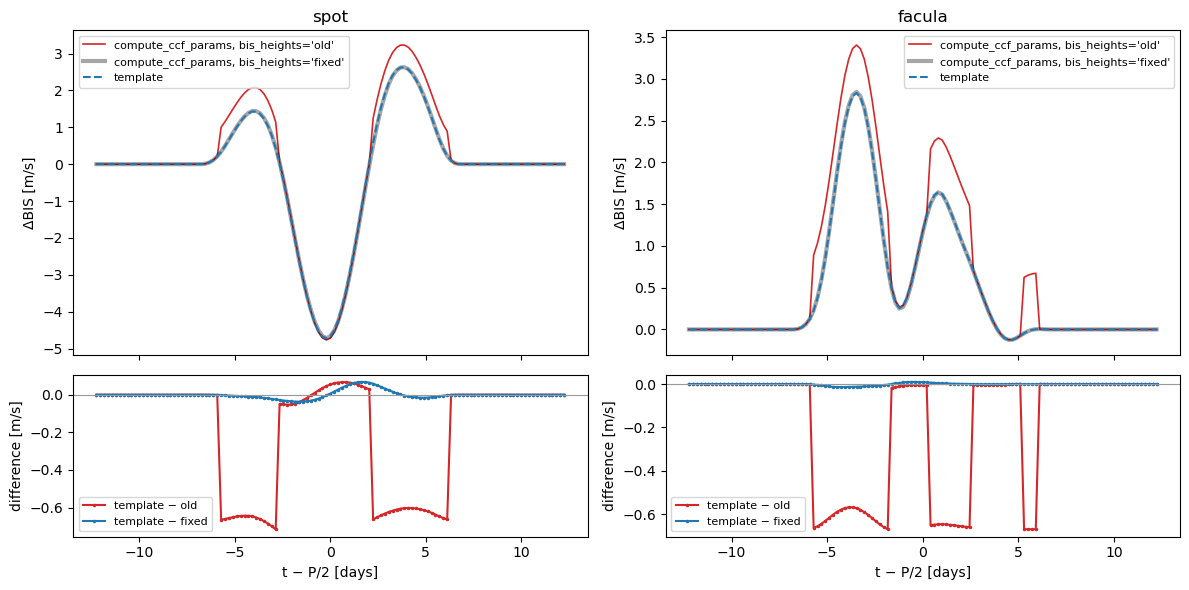

In [13]:
# compute_ccf_params with the old heights of the bisector (bis_heights='old': the mean of its 50 heights that fall in each
# band; these heights start 10 % above the wings, so the number of them in a band changes with the CCF) and with fixed
# heights in each band (bis_heights='fixed', the default)
bis_old = {}
for name in ind:
    sims[name].bis_heights = 'old'
    *_, ybis_all = sims[name].compute_ccf_params()
    b = sims[name].compute_ccf_params()[3]
    sims[name].bis_heights = 'fixed'
    bis_old[name] = b - b[0]
    ybis_all = np.array(ybis_all)
    n_bot = ((ybis_all >= 0.1) & (ybis_all <= 0.4)).sum(1)
    for label, ref in (('old heights', bis_old[name]), ('fixed heights', ind[name]['bis_gauss'])):
        d = ind[name]['bis_template'] - ref
        print('%-7s %-13s template - ref: rms %.3f m/s, max %.3f m/s' % (name, label, np.std(d), np.max(np.abs(d))))
    print('        old heights: %d epochs with %d heights in the bottom band instead of %d'
          % ((n_bot != n_bot[0]).sum(), n_bot[n_bot != n_bot[0]][0], n_bot[0]))

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j, name in enumerate(ind):
    r = ind[name]
    axes[0, j].plot(th, bis_old[name], color='C3', lw=1.2, label="compute_ccf_params, bis_heights='old'")
    axes[0, j].plot(th, r['bis_gauss'], 'k-', lw=3, alpha=0.35, label="compute_ccf_params, bis_heights='fixed'")
    axes[0, j].plot(th, r['bis_template'], 'C0--', label='template')
    axes[0, j].set_ylabel('ΔBIS [m/s]'); axes[0, j].set_title(name); axes[0, j].legend(fontsize=8)
    axes[1, j].plot(th, r['bis_template'] - bis_old[name], 'C3.-', ms=3, label='template − old')
    axes[1, j].plot(th, r['bis_template'] - r['bis_gauss'], 'C0.-', ms=3, label='template − fixed')
    axes[1, j].axhline(0, color='0.6', lw=0.8)
    axes[1, j].set_ylabel('difference [m/s]'); axes[1, j].set_xlabel('t − P/2 [days]'); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

#TODO test it on david baroch version

### Summary of section 6

Noise-free; numbers from the outputs above. `compute_ccf_params` measures the BIS at fixed heights in each band (`bis_heights='fixed'`, the default).

**Check (known deformations).** Each deformation alone is recovered to first order: a scale + offset gives Δcontrast = −2.000 % with no change in RV, FWHM or BIS; a tilted bisector of ε = 10 m/s gives ΔBIS = −4.996 m/s against −4.998 m/s for `compute_ccf_params`. The joint fit makes the RV insensitive to an offset (section 3 with the area normalisation: 0.48 m/s for an offset of 1 % of the maximum). With all the deformations ×5 (contrast −10 %, RV 50 m/s, ΔFWHM 35 m/s, ΔBIS −25 m/s) the template RV is 77.31 m/s against 77.46 m/s, once the shift terms are divided by 1 + a (without it, 10 % too small). The reference itself is not free of systematics: the gaussian fit on a fixed window gives ΔFWHM = −0.28 m/s for a pure shift of 10 m/s, and 7.14 m/s for a stretch whose true ΔFWHM is 6.98 m/s.

**Transits** (template − `compute_ccf_params`):

| | spot: peak to peak | spot: rms (max) diff. | facula: peak to peak | facula: rms (max) diff. |
|---|---|---|---|---|
| contrast | 0.28 % | 0.0014 % (0.004 %) | 0.25 % | 0.0006 % (0.002 %) |
| RV, joint fit | 11.6 m/s | 0.007 m/s (0.017) | 7.0 m/s | 0.003 m/s (0.009) |
| RV, section 3 | | 0.042 m/s (0.094) | | 0.022 m/s (0.054) |
| FWHM, stretch | 23.0 m/s | 0.20 m/s (0.61) | 11.7 m/s | 0.08 m/s (0.31) |
| FWHM, half height | | 0.55 m/s (1.20) | | 0.36 m/s (0.90) |
| BIS | 7.3 m/s | 0.021 m/s (0.068) | 3.0 m/s | 0.005 m/s (0.014) |
| BIS, `bis_heights='old'` | 8.0 m/s | 0.29 m/s (0.72) | 3.5 m/s | 0.29 m/s (0.67) |

- **Contrast and RV:** the same as the reference. The joint fit improves the RV by a factor of 6, because the offset and the scale are fitted instead of the area being normalised.
- **FWHM:** the stretch follows the gaussian FWHM to about 3 % of its peak to peak, and the difference is smooth. Part of it comes from the gaussian fit on a fixed window (see the check). The width at half height is a different quantity (it measures the flanks only) and departs more from the gaussian FWHM.
- **BIS:** the template BIS and `compute_ccf_params` agree to better than 1 % of the signal. With the old heights of the bisector (`bis_heights='old'`), `compute_ccf_params` jumps by about −0.65 m/s at the 35 epochs where its bisector has 17 heights in the bottom band instead of 16: these steps were an artefact of the old measurement, not of the template method, and they also made the old BIS peak to peak larger (8.0 against 7.3 m/s for the spot).

**Not tested here:** photon noise (weights 1/σ² in the least squares and in the band sums), and CCFs far from a gaussian.

## 7. Extreme cases: very asymmetric CCFs

Sections 4 to 6 compare the two methods on small changes of a nearly gaussian CCF. Here the CCF is pushed far from that:

1. **Synthetic deformations of the template** (7.1): a bisector tilted by up to 1 km/s, and a narrow feature (σ = 1 km/s) of 1, 5 and 20 % of the depth moved across the profile, like a spot on the line of a fast rotator.
2. **Big spots on the Sun** (7.2): radius 5 to 45°, RV up to ~500 m/s peak to peak.
3. **A fast rotator** (7.3): P = 2 d, vsini = 25 km/s. The CCF is a broad rotation profile with a flat top, far from a gaussian, and a spot draws a bump across it.

**Grids that keep the brightness (7.2, 7.3).** The grids of section 1 use `normalization=False`, which normalises the CCF of every ring by its own minimum (`CCF_grid`: −ccf/min(ccf) + 1). The brightness of the spectrum is then lost: a spot is not darker than the quiet photosphere, only its convective blueshift and its bisector differ. The spot of section 4 (11.6 m/s peak to peak, positive at the centre of the disc) is almost only the inhibition of the convective blueshift: with the blueshift and the bisector of the spot removed, its RV at the centre is −0.06 m/s. For the physical cases the grids are built with `normalization='none'` (the raw CCF, proportional to the spectrum): the spot is dark (0.55 × the quiet intensity) and the disc limb darkened, and a spot of 20° at the centre removes 7.9 % of the flux.

**Iterated template.** The template method is first order in C − T (section 3: 0.8 m/s error for a shift of 300 m/s). `template_iterated` shifts every CCF back by the RV found and measures it again (3 times). The part of the difference that the iteration removes comes from the first order approximation. The part that stays is a real difference between the two definitions of the indicators.

In [14]:
def reference(quiet, half_width=None):
    """Template (the CCF of the quiet star), window (between the wings of the template, as compute_ccf_params) and the
    indicators of the template (compute_ccf_params) of a simulation without regions. half_width [m/s]: only the
    velocities within half_width of the peak of the template (all the CCFs are cut the same way, see compare_ref)."""
    v, T = quiet.ccf_rv, quiet.ccf_var[0]
    keep = np.ones(len(v), dtype=bool) if half_width is None else np.abs(v - v[np.argmax(T)]) <= half_width
    v, T = v[keep], T[keep]
    c0 = T - T.min() + 0.000001
    cl, cr, _, _ = nbspectra.speed_bisector_nb(np.ascontiguousarray(v, dtype=np.float64), c0 / c0.max(), True)
    w = np.zeros(len(v), dtype=bool)
    w[int(cl):int(cr)] = True
    r, c, f, b = (x[0] for x in quiet.compute_ccf_params(rv=v, ccf=T[None, :])[:4])
    return dict(sim=quiet, keep=keep, rv=v, T=T, window=w, rv0=r, con0=c, fwhm0=f, bis0=b)


def template_iterated(ref, ccfs, n_iter=3):
    """template_indicators, iterated on the RV: every CCF is shifted back by the RV found (cubic spline) and measured
    again, n_iter times. The other indicators are those of the last iteration (a shift does not change them)."""
    v, T, w = ref['rv'], ref['T'], ref['window']
    ccfs = np.atleast_2d(ccfs)
    rv_tot = np.zeros(len(ccfs))
    for _ in range(n_iter):
        back = np.array([CubicSpline(v, c)(v + r) for c, r in zip(ccfs, rv_tot)])
        t = template_indicators(v, back, T, w, ref['rv0'])
        rv_tot = rv_tot + t['rv']
    t['rv'] = rv_tot
    return t


def compare_ref(ref, ccfs):
    """compare (section 6) for any quiet star (ref of reference()), with also the iterated template RV."""
    ccfs = np.atleast_2d(ccfs)[:, ref['keep']]
    rv_g, con_g, fwhm_g, bis_g, *_ = ref['sim'].compute_ccf_params(rv=ref['rv'], ccf=np.vstack([ref['T'], ccfs]))  # window of T
    t = template_indicators(ref['rv'], ccfs, ref['T'], ref['window'], ref['rv0'])
    ti = template_iterated(ref, ccfs)
    return dict(contrast_gauss=100 * (con_g[1:] / ref['con0'] - 1), contrast_template=100 * t['a'],
                rv_gauss=rv_g[1:] - ref['rv0'], rv_template=t['rv'], rv_iterated=ti['rv'],
                fwhm_gauss=fwhm_g[1:] - ref['fwhm0'], fwhm_template=t['s'] * ref['fwhm0'],
                fwhm_iterated=ti['s'] * ref['fwhm0'],
                bis_gauss=bis_g[1:] - ref['bis0'], bis_template=t['bis'], bis_iterated=ti['bis'])


def summary(results, keys=(('rv', 'm/s'), ('fwhm', 'm/s'), ('bis', 'm/s'), ('contrast', '%'))):
    """One row per case and indicator: peak to peak of compute_ccf_params, and template - compute_ccf_params (rms, max,
    max as a fraction of the peak to peak), first order and iterated."""
    rows = []
    for case, r in results.items():
        for q, unit in keys:
            g = r[q + '_gauss']
            row = {'case': case, 'indicator': '%s [%s]' % (q, unit), 'peak to peak': np.ptp(g)}
            for m in ('template', 'iterated'):
                if q + '_' + m in r:
                    d = r[q + '_' + m] - g
                    row['%s: rms' % m], row['%s: max' % m] = np.std(d), np.max(np.abs(d))
                    row['%s: max / ptp [%%]' % m] = 100 * np.max(np.abs(d)) / np.ptp(g)
            rows.append(row)
    return pd.DataFrame(rows).set_index(['case', 'indicator'])


ref_sun = reference(sims['quiet'])
print('quiet Sun: FWHM %.0f m/s, BIS %.1f m/s, window %.1f to %.1f km/s'
      % (ref_sun['fwhm0'], ref_sun['bis0'], rv[ref_sun['window']][0] / 1e3, rv[ref_sun['window']][-1] / 1e3))

quiet Sun: FWHM 6990 m/s, BIS -44.3 m/s, window -10.5 to 8.9 km/s


### 7.1 Synthetic deformations of the template

**Tilted bisector**: the template of section 1 with a shift that grows with the height, ε × y_T (0 at the bottom, ε at the top: ΔBIS ≈ −ε/2), up to ε = 1 km/s.

**A narrow feature**: the template minus a gaussian of σ = 1 km/s and 1, 5 or 20 % of the depth of the CCF, at positions from −6 to +6 km/s from the centre. This is how a dark spot changes the line of a star that rotates much faster than the width of the local line (Doppler imaging). Top: ΔRV and ΔBIS against the position of the feature; below each: template − `compute_ccf_params`.

tilted bisector (expected ΔBIS ≈ -tilt / 2):


,bis_gauss,bis_template,rv_gauss,rv_template,rv_iterated,fwhm_gauss,fwhm_template
tilt [m/s],,,,,,,
10,-4.9980,-4.9960,5.4410,5.4430,5.4430,-0.0690,0.0820
30,-14.9960,-14.9840,16.3210,16.3260,16.3280,-0.2890,0.3890
100,-49.9800,-49.9020,54.4000,54.3960,54.4140,-1.9100,2.9720
300,-149.9280,-149.2920,163.3370,163.1290,163.2160,-13.8850,23.2640
1000,-500.3630,-491.5600,552.7310,548.8430,546.6610,-148.7030,245.9710


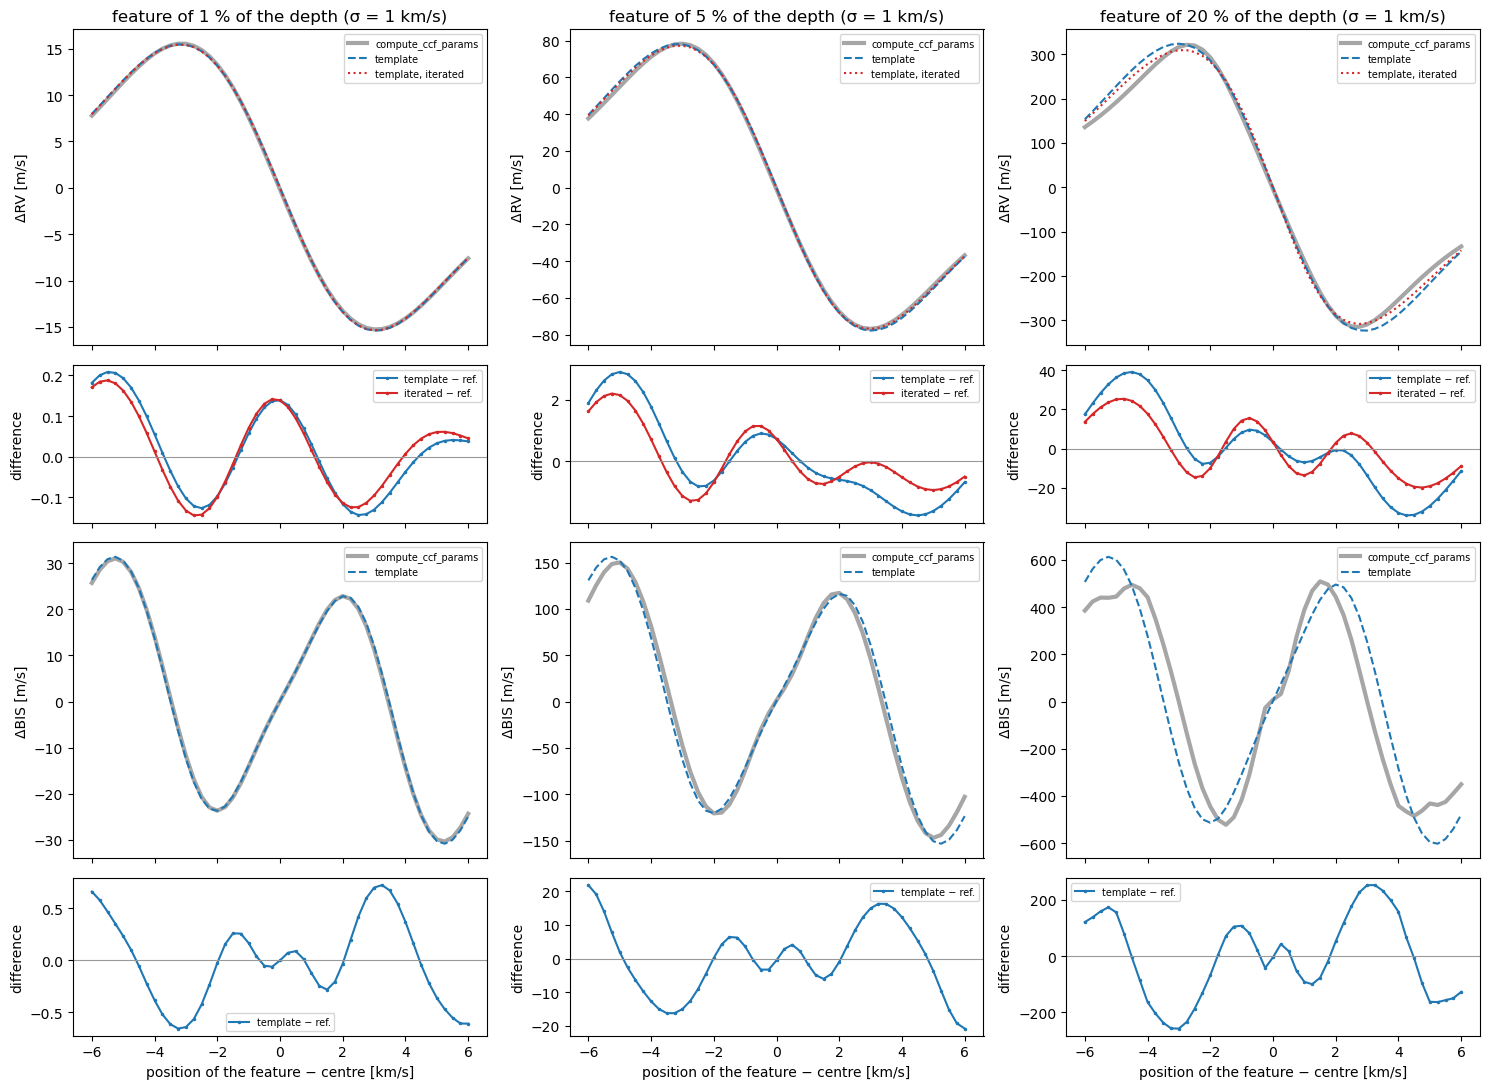

peak to peak  template: rms  template: max  \
case         indicator                                                  
feature 1 %  rv [m/s]           30.8060         0.1070         0.2080   
             fwhm [m/s]         79.8100         0.9840         2.1600   
             bis [m/s]          61.4300         0.3970         0.7210   
             contrast [%]        0.7670         0.0060         0.0110   
feature 5 %  rv [m/s]          155.0660         1.3600         2.8970   
             fwhm [m/s]        398.7750         8.2030        16.6860   
             bis [m/s]         297.2770        10.5960        21.8420   
             contrast [%]        3.8160         0.0270         0.0880   
feature 20 % rv [m/s]          636.0450        20.7850        39.2010   
             fwhm [m/s]       1606.7780       115.5130       196.3320   
             bis [m/s]        1031.4870       145.7820       258.4770   
             contrast [%]       14.8850         0.3770         1.4210   

                           template: max / ptp [%]  iterated: rms  \
case         indicator                                              
feature 1 %  rv [m/s]                       0.6760         0.1010   
             fwhm [m/s]                     2.7060         0.9670   
             bis [m/s]                      1.1730         0.2660   
             contrast [%]                   1.3920            NaN   
feature 5 %  rv [m/s]                       1.8680         0.9990   
             fwhm [m/s]                     4.1840         5.0940   
             bis [m/s]                      7.3470         6.9880   
             contrast [%]                   2.2940            NaN   
feature 20 % rv [m/s]                       6.1630        13.8590   
             fwhm [m/s]                    12.2190        41.4780   
             bis [m/s]                     25.0590        83.9790   
             contrast [%]                   9.5460            NaN   

                           iterated: max  iterated: max / ptp [%]  
case         indicator                                             
feature 1 %  rv [m/s]             0.1880                   0.6090  
             fwhm [m/s]           2.0470                   2.5650  
             bis [m/s]            0.5570                   0.9070  
             contrast [%]            NaN                      NaN  
feature 5 %  rv [m/s]             2.1960                   1.4160  
             fwhm [m/s]          10.9770                   2.7530  
             bis [m/s]           19.3310                   6.5030  
             contrast [%]            NaN                      NaN  
feature 20 % rv [m/s]            25.4710                   4.0050  
             fwhm [m/s]          72.2900                   4.4990  
             bis [m/s]          172.1440                  16.6890  
             contrast [%]            NaN                      NaN

In [15]:
# synthetic: the template tilted (a bisector that leans more and more) and the template with a narrow feature
spl = CubicSpline(rv, template)
yT = (template - template.min()) / (template.max() - template.min())
depth = template.max() - template.min()
eps = np.array([10, 30, 100, 300, 1000])                                  # [m/s] tilt of the bisector (top - bottom)
tilted = np.array([spl(rv - e * yT) for e in eps])
amps = [0.01, 0.05, 0.2]                                                  # depth of the feature / depth of the CCF
sigma_b = 1000.0                                                          # [m/s] width of the feature
v_b = np.linspace(-6000, 6000, 49) + rv_T                                 # [m/s] position of the feature
bumped = {A: np.array([template - A * depth * np.exp(-0.5 * ((rv - x) / sigma_b) ** 2) for x in v_b]) for A in amps}
syn = {'tilt': compare_ref(ref_sun, tilted)}
syn.update({A: compare_ref(ref_sun, bumped[A]) for A in amps})

tab = pd.DataFrame({k: syn['tilt'][k] for k in ('bis_gauss', 'bis_template', 'rv_gauss', 'rv_template', 'rv_iterated',
                                                 'fwhm_gauss', 'fwhm_template')}, index=pd.Index(eps, name='tilt [m/s]'))
print('tilted bisector (expected ΔBIS ≈ -tilt / 2):')
display(tab.round(3))

fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharex='col', gridspec_kw=dict(height_ratios=[2, 1, 2, 1]))
for j, A in enumerate(amps):
    r = syn[A]
    x = (v_b - rv_T) / 1e3
    for k, (q, lab) in enumerate((('rv', 'ΔRV [m/s]'), ('bis', 'ΔBIS [m/s]'))):
        ax, axd = axes[2 * k, j], axes[2 * k + 1, j]
        ax.plot(x, r[q + '_gauss'], 'k-', lw=3, alpha=0.35, label='compute_ccf_params')
        ax.plot(x, r[q + '_template'], 'C0--', label='template')
        axd.plot(x, r[q + '_template'] - r[q + '_gauss'], 'C0.-', ms=3, label='template − ref.')
        if q + '_iterated' in r and q == 'rv':
            ax.plot(x, r[q + '_iterated'], 'C3:', label='template, iterated')
            axd.plot(x, r[q + '_iterated'] - r[q + '_gauss'], 'C3.-', ms=3, label='iterated − ref.')
        axd.axhline(0, color='0.6', lw=0.8)
        ax.set_ylabel(lab); axd.set_ylabel('difference')
        ax.legend(fontsize=7); axd.legend(fontsize=7)
    axes[0, j].set_title('feature of %g %% of the depth (σ = %.0f km/s)' % (100 * A, sigma_b / 1e3))
    axes[-1, j].set_xlabel('position of the feature − centre [km/s]')
plt.tight_layout(); plt.show()
display(summary({'feature %g %%' % (100 * A): syn[A] for A in amps}).round(3))

### 7.2 Big spots on the Sun

One spot on the equator (as in section 4, P = 24.47 d), radius 5, 10, 20, 30 and 45°, with the grids that keep the brightness (`grids_none`). Bottom panels: the difference between the methods as a fraction of the peak to peak of `compute_ccf_params`.

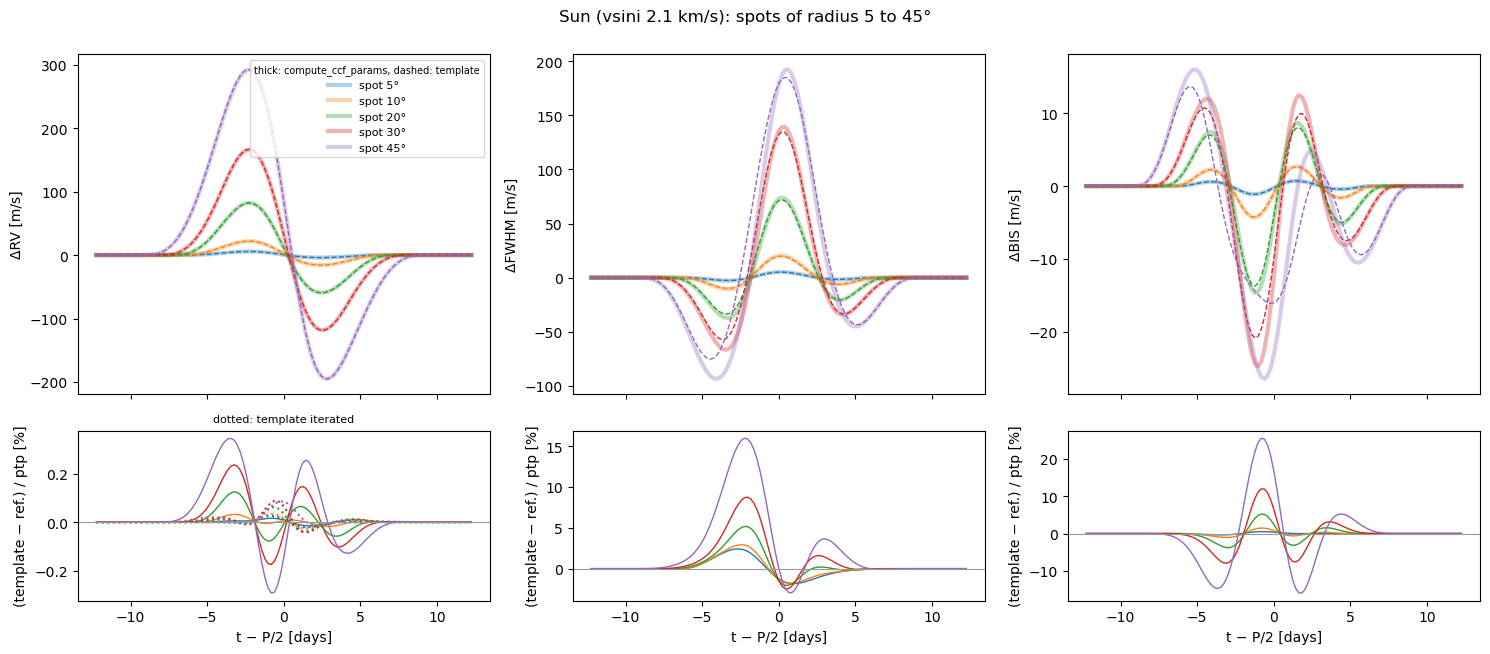

peak to peak  template: rms  template: max  \
case     indicator                                                  
spot 5°  rv [m/s]            9.5670         0.0010         0.0020   
         fwhm [m/s]          7.9440         0.0730         0.1920   
         bis [m/s]           1.8350         0.0030         0.0090   
         contrast [%]        0.5990         0.0010         0.0010   
spot 10° rv [m/s]           37.7310         0.0030         0.0120   
         fwhm [m/s]         30.9430         0.3110         0.9050   
         bis [m/s]           7.0350         0.0310         0.1030   
         contrast [%]        2.3610         0.0020         0.0060   
spot 20° rv [m/s]          141.4950         0.0550         0.1760   
         fwhm [m/s]        111.1540         1.6370         5.7380   
         bis [m/s]          23.3870         0.3750         1.2250   
         contrast [%]        8.8910         0.0100         0.0340   
spot 30° rv [m/s]          284.5810         0.2260         0.6710   
         fwhm [m/s]        205.9310         4.9090        18.0250   
         bis [m/s]          37.2910         1.3840         4.4670   
         contrast [%]       18.1520         0.0360         0.1060   
spot 45° rv [m/s]          486.7570         0.6390         1.6800   
         fwhm [m/s]        285.8040        12.9260        45.6120   
         bis [m/s]          42.5270         3.4980        10.8520   
         contrast [%]       33.1990         0.1000         0.3310   

                       template: max / ptp [%]  iterated: rms  iterated: max  \
case     indicator                                                             
spot 5°  rv [m/s]                       0.0160         0.0010         0.0020   
         fwhm [m/s]                     2.4150         0.0710         0.1800   
         bis [m/s]                      0.5160         0.0020         0.0060   
         contrast [%]                   0.2250            NaN            NaN   
spot 10° rv [m/s]                       0.0320         0.0040         0.0130   
         fwhm [m/s]                     2.9240         0.2840         0.7050   
         bis [m/s]                      1.4630         0.0120         0.0400   
         contrast [%]                   0.2520            NaN            NaN   
spot 20° rv [m/s]                       0.1240         0.0220         0.0880   
         fwhm [m/s]                     5.1620         1.1000         2.6080   
         bis [m/s]                      5.2370         0.0720         0.3000   
         contrast [%]                   0.3800            NaN            NaN   
spot 30° rv [m/s]                       0.2360         0.0600         0.2500   
         fwhm [m/s]                     8.7530         2.3070         5.4410   
         bis [m/s]                     11.9790         0.2150         0.9130   
         contrast [%]                   0.5830            NaN            NaN   
spot 45° rv [m/s]                       0.3450         0.0990         0.4170   
         fwhm [m/s]                    15.9590         4.1100         9.0850   
         bis [m/s]                     25.5190         0.4150         1.6880   
         contrast [%]                   0.9970            NaN            NaN   

                       iterated: max / ptp [%]  
case     indicator                              
spot 5°  rv [m/s]                       0.0260  
         fwhm [m/s]                     2.2690  
         bis [m/s]                      0.3180  
         contrast [%]                      NaN  
spot 10° rv [m/s]                       0.0340  
         fwhm [m/s]                     2.2780  
         bis [m/s]                      0.5650  
         contrast [%]                      NaN  
spot 20° rv [m/s]                       0.0620  
         fwhm [m/s]                     2.3460  
         bis [m/s]                      1.2810  
         contrast [%]                      NaN  
spot 30° rv [m/s]                       0.0880  
        

In [16]:
# grids that keep the brightness of every spectrum (normalization='none'): a spot is dark, the disc limb darkened
def grids_none(rv_g):
    """CCF grids of the quiet photosphere, the spot and the facula as in section 1, with normalization='none'."""
    def make(flux, cb, bisector):
        gr = CCF_grid(N_rings, flux, rv_g, wvm, fm, convective_blueshift=cb, phoenix_resolution=True, normalization='none')
        gr.built_grid(bisector=bisector)
        return gr
    return dict(ccf_grid_qp=make(flux_quiet, 0, None), ccf_grid_sp=make(flux_sp, 1, dumusque_bisector(normalization=False)),
                ccf_grid_fc=make(flux_fc, 0, None))


def transits(P, regions, grids, n=121):
    """One rotation of period P [days] (121 epochs, the regions cross the centre at P/2): the quiet star and every
    entry of regions ({name: [active_region, ...]}). Returns the times - P/2 and the simulations."""
    t = np.linspace(0, P, n)
    out = {}
    for name, reg in [('quiet', [])] + list(regions.items()):
        ss = StarSim(t, N_rings, inclination=inclination, rotation_period=P, differential_rotation=0,
                     active_regions_map=reg, mode=['ccf'], stellar_radius=1, **grids)
        ss.generate_timeseries(verbose=False)
        out[name] = ss
    return t - P / 2, out


def plot_transits(th_, res_, title):
    """compute_ccf_params (thick) and template (dashed) for every case; below, the difference as a fraction of the peak
    to peak of compute_ccf_params (dotted: RV of the iterated template)."""
    fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for k, (q, lab) in enumerate((('rv', 'ΔRV [m/s]'), ('fwhm', 'ΔFWHM [m/s]'), ('bis', 'ΔBIS [m/s]'))):
        for i, (case, r) in enumerate(res_.items()):
            col = 'C%d' % i
            axes[0, k].plot(th_, r[q + '_gauss'], '-', color=col, lw=3, alpha=0.35, label=case)
            axes[0, k].plot(th_, r[q + '_template'], '--', color=col, lw=1)
            axes[1, k].plot(th_, 100 * (r[q + '_template'] - r[q + '_gauss']) / np.ptp(r[q + '_gauss']), '-', color=col, lw=1)
            if q == 'rv':
                axes[1, k].plot(th_, 100 * (r['rv_iterated'] - r['rv_gauss']) / np.ptp(r['rv_gauss']), ':', color=col)
        axes[0, k].set_ylabel(lab); axes[1, k].set_ylabel('(template − ref.) / ptp [%]'); axes[1, k].set_xlabel('t − P/2 [days]')
        axes[1, k].axhline(0, color='0.6', lw=0.8)
    axes[0, 0].legend(fontsize=8, title='thick: compute_ccf_params, dashed: template', title_fontsize=7)
    axes[1, 0].set_title('dotted: template iterated', fontsize=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


# big spots on the Sun (P = 24.47 d, vsini 2 km/s)
grids_sun = grids_none(rv_grid)
th_sun, sun_sims = transits(rotation_period, {'spot %d°' % R: [active_region('sp', R, 90, 180)] for R in (5, 10, 20, 30, 45)},
                            grids_sun)
ref_sun_none = reference(sun_sims['quiet'])
big = {name: compare_ref(ref_sun_none, ss.ccf_var) for name, ss in sun_sims.items() if name != 'quiet'}
plot_transits(th_sun, big, 'Sun (vsini %.1f km/s): spots of radius 5 to 45°' % (sun_sims['quiet'].vsini / 1e3))
display(summary(big).round(3))

### 7.3 A fast rotator

The same spectra on a star with P = 2 d (vsini = 25 km/s, no differential rotation), on a grid of ±60 km/s: spots of 10° and 20°, and a facula of 20°. The template is the CCF of the quiet star, a rotation profile with a flat top. A spot removes the light of one part of the disc, so it draws a dip at its own velocity, which moves across the profile during the rotation (middle panel; the offset is the loss of continuum).

fast rotator: vsini 25.3 km/s, FWHM (gaussian fit) 42.1 km/s, window -36.3 to 31.9 km/s


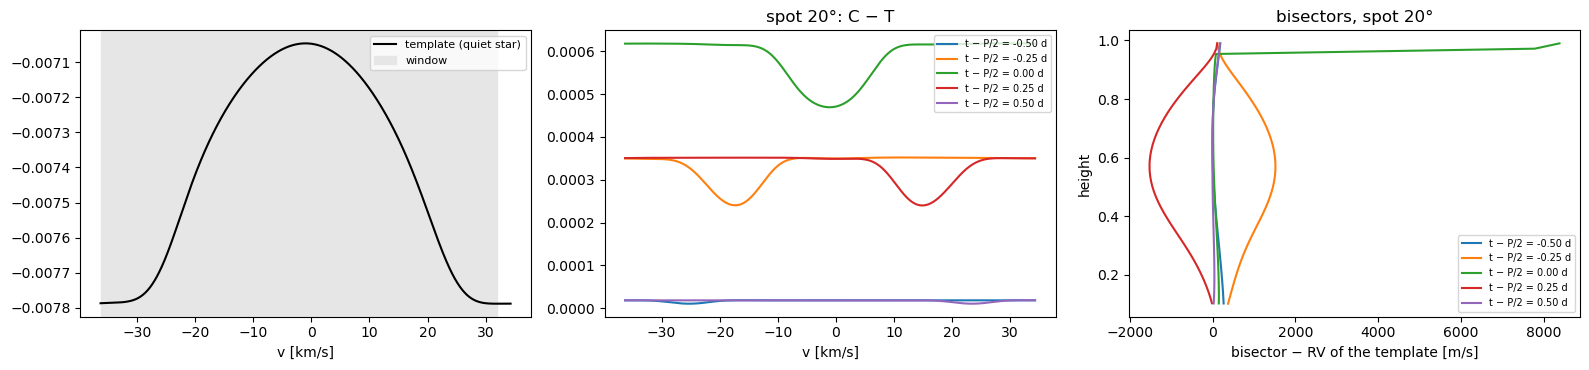

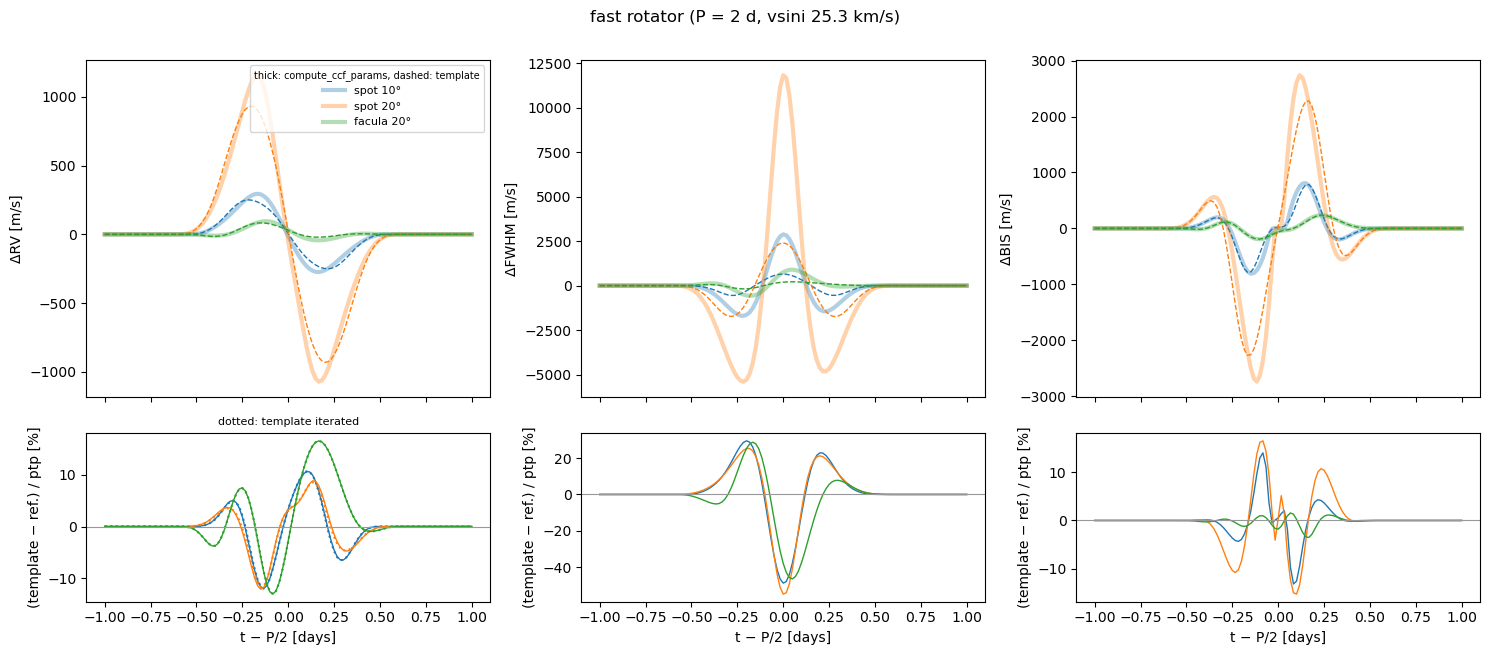

peak to peak  template: rms  template: max  \
case       indicator                                                  
spot 10°   rv [m/s]          569.6720        23.4640        68.6540   
           fwhm [m/s]       4577.9800       662.5250      2230.5130   
           bis [m/s]        1619.7400        54.5980       227.9870   
           contrast [%]        6.0880         1.4860         5.0370   
spot 20°   rv [m/s]         2230.8280        81.1110       271.8760   
           fwhm [m/s]      17224.0580      2542.7930      9429.4120   
           bis [m/s]        5476.9150       291.3330       907.7910   
           contrast [%]       24.8730         5.7040        22.6470   
facula 20° rv [m/s]          139.2740         7.9420        23.1450   
           fwhm [m/s]       1473.6430       199.6740       684.1160   
           bis [m/s]         428.7780         3.2370        15.2000   
           contrast [%]        1.8270         0.4520         1.5200   

                         template: max / ptp [%]  iterated: rms  \
case       indicator                                              
spot 10°   rv [m/s]                      12.0510        23.3890   
           fwhm [m/s]                    48.7230       658.0300   
           bis [m/s]                     14.0760        46.5860   
           contrast [%]                  82.7410            NaN   
spot 20°   rv [m/s]                      12.1870        78.4540   
           fwhm [m/s]                    54.7460      2490.5730   
           bis [m/s]                     16.5750       198.7870   
           contrast [%]                  91.0490            NaN   
facula 20° rv [m/s]                      16.6190         7.9350   
           fwhm [m/s]                    46.4230       199.4520   
           bis [m/s]                      3.5450         3.0130   
           contrast [%]                  83.1530            NaN   

                         iterated: max  iterated: max / ptp [%]  
case       indicator                                             
spot 10°   rv [m/s]            68.5890                  12.0400  
           fwhm [m/s]        2230.5030                  48.7220  
           bis [m/s]          209.2980                  12.9220  
           contrast [%]            NaN                      NaN  
spot 20°   rv [m/s]           262.4220                  11.7630  
           fwhm [m/s]        9429.3360                  54.7450  
           bis [m/s]          732.9800                  13.3830  
           contrast [%]            NaN                      NaN  
facula 20° rv [m/s]            23.1620                  16.6300  
           fwhm [m/s]         684.1190                  46.4240  
           bis [m/s]           14.0540                   3.2780  
           contrast [%]            NaN                      NaN

In [17]:
# fast rotator: P = 2 days (vsini ~ 25 km/s), the same spectra on a wider velocity grid
P_fast = 2.0
grids_fast = grids_none(np.arange(-60000, 60025, 25))
th_fast, fast_sims = transits(P_fast, {'spot 10°': [active_region('sp', 10, 90, 180)],
                                       'spot 20°': [active_region('sp', 20, 90, 180)],
                                       'facula 20°': [active_region('fc', 20, 90, 180)]}, grids_fast)
# the continuum of this CCF is flat with small ripples, and the wing found by speed_bisector_nb jumps between them (the
# gaussian FWHM changes by several km/s with the width of the grid): all the CCFs are cut to vsini + 10 km/s around the
# peak, the same window for both methods
ref_fast = reference(fast_sims['quiet'], half_width=fast_sims['quiet'].vsini + 10000)
v_f, T_f = ref_fast['rv'], ref_fast['T']
print('fast rotator: vsini %.1f km/s, FWHM (gaussian fit) %.1f km/s, window %.1f to %.1f km/s'
      % (fast_sims['quiet'].vsini / 1e3, ref_fast['fwhm0'] / 1e3, v_f[ref_fast['window']][0] / 1e3,
         v_f[ref_fast['window']][-1] / 1e3))
fast = {name: compare_ref(ref_fast, ss.ccf_var) for name, ss in fast_sims.items() if name != 'quiet'}

# the CCFs: template, the spot of 20° at a few phases (difference with the template) and their bisectors
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(v_f / 1e3, T_f, 'k', label='template (quiet star)')
axes[0].axvspan(v_f[ref_fast['window']][0] / 1e3, v_f[ref_fast['window']][-1] / 1e3, color='0.9', zorder=0, label='window')
phases = (30, 45, 60, 75, 90)
for k in phases:
    axes[1].plot(v_f / 1e3, fast_sims['spot 20°'].ccf_var[k][ref_fast['keep']] - T_f, label='t − P/2 = %.2f d' % th_fast[k])
*_, xb, yb = fast_sims['spot 20°'].compute_ccf_params(rv=v_f, ccf=fast_sims['spot 20°'].ccf_var[:, ref_fast['keep']])
for k in phases:
    axes[2].plot(np.array(xb[k]) - ref_fast['rv0'], yb[k], label='t − P/2 = %.2f d' % th_fast[k])
axes[0].set_xlabel('v [km/s]'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('v [km/s]'); axes[1].set_title('spot 20°: C − T'); axes[1].legend(fontsize=7)
axes[2].set_xlabel('bisector − RV of the template [m/s]'); axes[2].set_ylabel('height'); axes[2].legend(fontsize=7)
axes[2].set_title('bisectors, spot 20°')
plt.tight_layout(); plt.show()

plot_transits(th_fast, fast, 'fast rotator (P = %g d, vsini %.1f km/s)' % (P_fast, fast_sims['quiet'].vsini / 1e3))
display(summary(fast).round(3))

### Summary of section 7

Noise-free; numbers from the outputs above (difference template − `compute_ccf_params`, maximum over the rotation, as a fraction of the peak to peak of `compute_ccf_params`; in brackets: iterated template).

| case | RV | FWHM | BIS | contrast |
|---|---|---|---|---|
| tilted bisector, ε = 100 m/s | 0.01 % | **opposite sign** | 0.2 % | |
| tilted bisector, ε = 1 km/s | 0.7 % (1.1 %) | **opposite sign** | 1.8 % | |
| feature 1 % of the depth | 0.7 % (0.6 %) | 2.7 % (2.6 %) | 1.2 % (0.9 %) | 1.4 % |
| feature 5 % | 1.9 % (1.4 %) | 4.2 % (2.8 %) | 7.3 % (6.5 %) | 2.3 % |
| feature 20 % | 6.2 % (4.0 %) | 12 % (4.5 %) | 25 % (17 %) | 9.5 % |
| Sun, spot 10° (RV 38 m/s ptp) | 0.03 % | 2.9 % (2.3 %) | 1.5 % (0.6 %) | 0.3 % |
| Sun, spot 20° (141 m/s) | 0.12 % (0.06 %) | 5.2 % (2.3 %) | 5.2 % (1.3 %) | 0.4 % |
| Sun, spot 45° (487 m/s) | 0.35 % (0.09 %) | 16 % (3.2 %) | 26 % (4.0 %) | 1.0 % |
| fast rotator, spot 10° (570 m/s) | 12 % (12 %) | 49 % (49 %) | 14 % (13 %) | 83 % |
| fast rotator, spot 20° (2.2 km/s) | 12 % (12 %) | 55 % (55 %) | 17 % (13 %) | 91 % |
| fast rotator, facula 20° (139 m/s) | 17 % (17 %) | 46 % (46 %) | 3.5 % (3.3 %) | 83 % |

- **Tilted bisector.** RV and BIS agree to better than 2 % even for a tilt of 1 km/s. The FWHM does not: `compute_ccf_params` gives a narrower CCF (−149 m/s for ε = 1 km/s), the template stretch a wider one (+246 m/s). A tilted profile is not a stretched one, so the stretch term of the joint fit takes part of the asymmetry. For asymmetric changes the two FWHMs are different quantities.
- **Big spots on the Sun.** The RV stays the same (< 0.4 %, < 0.1 % iterated) up to a spot of 45° and 490 m/s peak to peak. The first-order template drifts away in FWHM and BIS as the spot grows (16 % and 26 % for 45°). The iteration brings them back to 3 and 4 %, so that drift is mostly the first order approximation, not the asymmetry.
- **Narrow features and the fast rotator.** Here the CCF is far from a gaussian and the iteration no longer helps. The two methods give different answers: 12–17 % of the RV, ~50 % of the FWHM, 13–17 % of the BIS. The gaussian fit of a flat-topped rotation profile is itself unstable. With a spot of 20° its FWHM swings by 17 km/s (40 % of the FWHM), and the FWHM of the quiet star changes by several km/s with the window alone (38.0, 42.6 and 41.8 km/s with grids of ±60, ±45 and ±80 km/s, before the cut at vsini + 10 km/s used here). The contrast of the template (the scale a of the joint fit) and the amplitude of the gaussian no longer measure the same thing (83–91 %).
- **In short.** For CCFs close to a gaussian, even with large asymmetric changes (big spots, tilted bisectors), the template gives the same RV and BIS as `compute_ccf_params`, iterated when the RV is above ~100 m/s. Neither method has a "true" value to aim at. Once the CCF is far from a gaussian (fast rotators, features deeper than a few % of the line), they measure different things, and the FWHM and the contrast must be defined again for that kind of profile.
- **For sections 4 to 6:** their spot is not dark (`normalization=False`, see the start of section 7). With `normalization='none'` the spot of 10° has 38 m/s of RV peak to peak instead of 11.6, and the agreement between the methods is as good (RV 0.03 %, BIS 1.5 %).